# Hotel Booking Cancellation: Exploratory Data Analysis

This notebook profiles the Hotel Booking Demand dataset for the booking-creation prediction setting. The target is `is_canceled` (`1` = canceled, `0` = not canceled).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style='whitegrid')

In [2]:
data_candidates = [
    Path('data/raw/hotel_bookings.csv'),
    Path('../data/raw/hotel_bookings.csv'),
]
data_path = next((path for path in data_candidates if path.exists()), None)
if data_path is None:
    raise FileNotFoundError('Download the Kaggle CSV to data/raw/hotel_bookings.csv before running this notebook.')

df = pd.read_csv(data_path, na_values=['NULL'])
print(f'Dataset path: {data_path}')
print(f'Shape: {df.shape}')
df.head()

Dataset path: data\raw\hotel_bookings.csv
Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
required_columns = {'is_canceled', 'reservation_status', 'reservation_status_date'}
missing_required = required_columns.difference(df.columns)
assert not missing_required, f'Missing required columns: {missing_required}'
assert set(df['is_canceled'].dropna().unique()).issubset({0, 1})

display(df.dtypes.to_frame('dtype'))
display(df.isna().sum().sort_values(ascending=False).to_frame('missing_values'))
print(f'Exact duplicate rows: {df.duplicated().sum():,}')
print('Duplicates are retained for now: the dataset has no booking identifier to distinguish duplicate records from legitimate identical bookings.')

,dtype
hotel,str
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,str
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


,missing_values
company,112593
agent,16340
country,488
children,4
arrival_date_month,0
arrival_date_week_number,0
hotel,0
is_canceled,0
stays_in_weekend_nights,0
arrival_date_day_of_month,0


Exact duplicate rows: 31,994
Duplicates are retained for now: the dataset has no booking identifier to distinguish duplicate records from legitimate identical bookings.


,count,rate
is_canceled,,
0,75166,0.629584
1,44224,0.370416


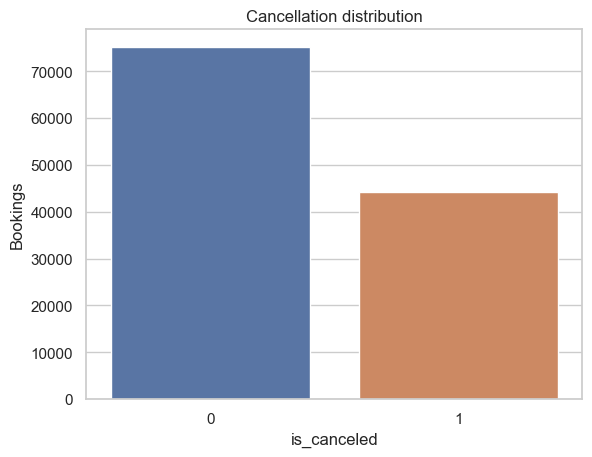

In [4]:
target_counts = df['is_canceled'].value_counts().sort_index()
target_rates = df['is_canceled'].value_counts(normalize=True).sort_index()
display(pd.DataFrame({'count': target_counts, 'rate': target_rates}))

ax = sns.countplot(data=df, x='is_canceled', hue='is_canceled', legend=False)
ax.set(title='Cancellation distribution', xlabel='is_canceled', ylabel='Bookings')
plt.show()

## Leakage and prediction-time feature audit

The primary model is defined at **booking creation**. The source dataset does not include field-level timestamps, so uncertain lifecycle fields are excluded conservatively.

In [5]:
feature_audit = pd.DataFrame([
    ('is_canceled', 'Exclude', 'Prediction target.'),
    ('reservation_status', 'Exclude', 'Final outcome status; direct target leakage.'),
    ('reservation_status_date', 'Exclude', 'Final-status timing; direct target leakage.'),
    ('assigned_room_type', 'Exclude', 'May be assigned or changed after the booking is created.'),
    ('booking_changes', 'Exclude', 'Accumulates changes after the original booking.'),
    ('days_in_waiting_list', 'Exclude', 'Can accumulate during the reservation lifecycle.'),
    ('required_car_parking_spaces', 'Conditional', 'Use only if frozen at creation; otherwise exclude.'),
    ('total_of_special_requests', 'Conditional', 'Use only if frozen at creation; otherwise exclude.'),
    ('arrival/stay/guest/booking-history fields', 'Candidate', 'Available at creation if captured in the reservation record.'),
    ('reserved_room_type', 'Candidate', 'Requested room at creation; do not substitute assigned_room_type.'),
    ('adr', 'Candidate', 'Use only if it is the price quoted at booking time.'),
], columns=['feature_or_group', 'decision', 'reason'])
feature_audit

,feature_or_group,decision,reason
0,is_canceled,Exclude,Prediction target.
1,reservation_status,Exclude,Final outcome status; direct target leakage.
2,reservation_status_date,Exclude,Final-status timing; direct target leakage.
3,assigned_room_type,Exclude,May be assigned or changed after the booking i...
4,booking_changes,Exclude,Accumulates changes after the original booking.
5,days_in_waiting_list,Exclude,Can accumulate during the reservation lifecycle.
6,required_car_parking_spaces,Conditional,Use only if frozen at creation; otherwise excl...
7,total_of_special_requests,Conditional,Use only if frozen at creation; otherwise excl...
8,arrival/stay/guest/booking-history fields,Candidate,Available at creation if captured in the reser...
9,reserved_room_type,Candidate,Requested room at creation; do not substitute ...


,count,mean,std,min,25%,50%,75%,max
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0
is_repeated_guest,119390.0,0.031912,0.175767,0.00,0.00,0.000,0.0,1.0


,correlation_with_is_canceled
lead_time,0.293123
total_of_special_requests,-0.234658
required_car_parking_spaces,-0.195498
booking_changes,-0.144381
previous_cancellations,0.110133
is_repeated_guest,-0.084793
agent,-0.083114
adults,0.060017
previous_bookings_not_canceled,-0.057358
days_in_waiting_list,0.054186


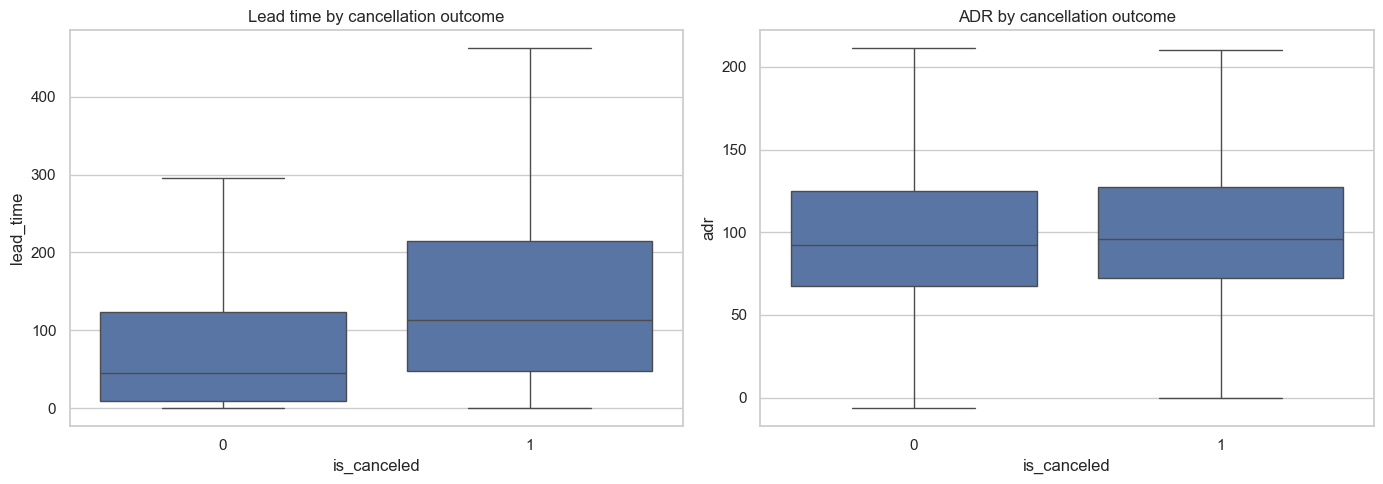

In [6]:
numeric_columns = df.select_dtypes(include=np.number).columns.drop('is_canceled')
display(df[numeric_columns].describe().T)

correlations = (
    df[numeric_columns.tolist() + ['is_canceled']]
    .corr(numeric_only=True)['is_canceled']
    .drop('is_canceled')
    .sort_values(key=np.abs, ascending=False)
)
display(correlations.to_frame('correlation_with_is_canceled'))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x='is_canceled', y='lead_time', showfliers=False, ax=axes[0])
axes[0].set_title('Lead time by cancellation outcome')
sns.boxplot(data=df, x='is_canceled', y='adr', showfliers=False, ax=axes[1])
axes[1].set_title('ADR by cancellation outcome')
plt.tight_layout()

In [7]:
categorical_columns = [
    'hotel', 'meal', 'market_segment', 'distribution_channel', 'deposit_type',
    'customer_type', 'reserved_room_type', 'is_repeated_guest'
]

for column in categorical_columns:
    rates = (
        df.groupby(column, dropna=False)['is_canceled']
        .agg(bookings='size', cancellation_rate='mean')
        .sort_values('cancellation_rate', ascending=False)
    )
    print(f'\nCancellation rate by {column}')
    display(rates)


Cancellation rate by hotel


,bookings,cancellation_rate
hotel,,
City Hotel,79330,0.417270
Resort Hotel,40060,0.277634



Cancellation rate by meal


,bookings,cancellation_rate
meal,,
FB,798,0.598997
BB,92310,0.373849
SC,10650,0.372394
HB,14463,0.344603
Undefined,1169,0.244654



Cancellation rate by market_segment


,bookings,cancellation_rate
market_segment,,
Undefined,2,1.000000
Groups,19811,0.610620
Online TA,56477,0.367211
Offline TA/TO,24219,0.343160
Aviation,237,0.219409
Corporate,5295,0.187347
Direct,12606,0.153419
Complementary,743,0.130552


... (6 outputs left out)


Cancellation rate by reserved_room_type


,bookings,cancellation_rate
reserved_room_type,,
P,12,1.000000
H,601,0.407654
A,85994,0.391074
G,2094,0.364374
L,6,0.333333
C,932,0.330472
B,1118,0.329159
D,19201,0.317796
F,2897,0.303763



Cancellation rate by is_repeated_guest


,bookings,cancellation_rate
is_repeated_guest,,
0,115580,0.377851
1,3810,0.144882


,feature,outlier_count,outlier_rate
6,adults,29710,0.248848
12,booking_changes,18076,0.151403
7,children,8590,0.071949
17,required_car_parking_spaces,7416,0.062116
10,previous_cancellations,6484,0.054309
9,is_repeated_guest,3810,0.031912
16,adr,3793,0.031770
15,days_in_waiting_list,3698,0.030974
11,previous_bookings_not_canceled,3620,0.030321
5,stays_in_week_nights,3354,0.028093


IQR flags indicate unusual values, not automatic data errors. Any clipping or transformation must be selected using training data only.


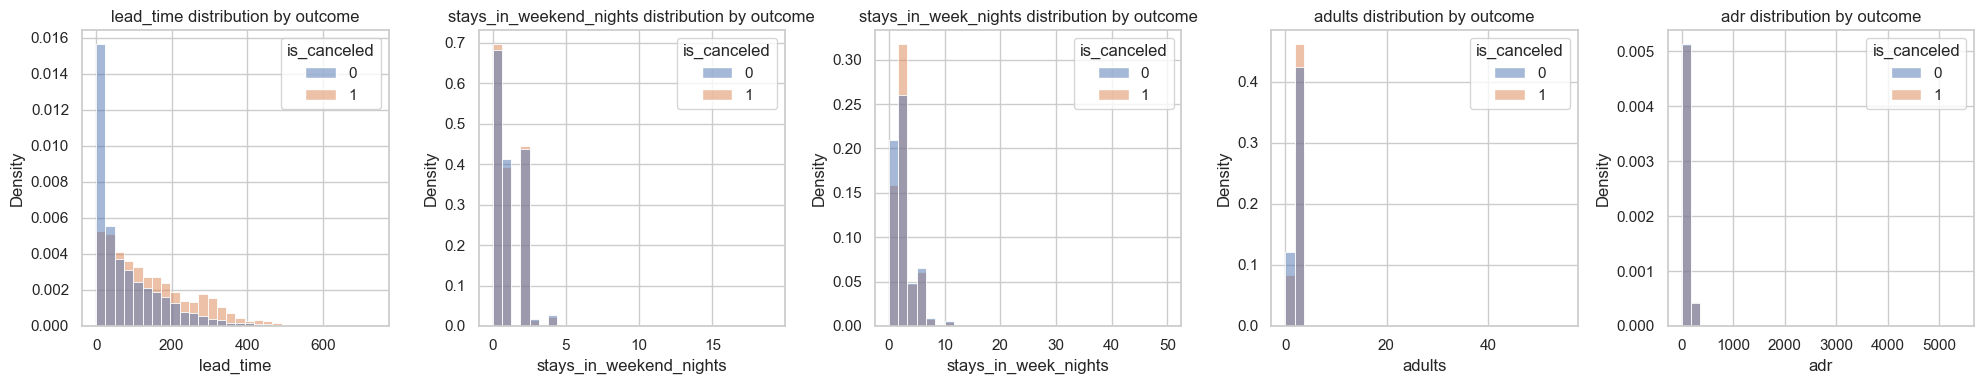

In [8]:
distribution_columns = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'adr']
fig, axes = plt.subplots(1, len(distribution_columns), figsize=(20, 4))
for axis, column in zip(axes, distribution_columns):
    sns.histplot(data=df, x=column, hue='is_canceled', bins=30, stat='density', common_norm=False, ax=axis)
    axis.set_title(f'{column} distribution by outcome')
plt.tight_layout()

outlier_rows = []
for column in numeric_columns:
    first_quartile, third_quartile = df[column].quantile([0.25, 0.75])
    iqr = third_quartile - first_quartile
    lower_bound = first_quartile - 1.5 * iqr
    upper_bound = third_quartile + 1.5 * iqr
    outlier_rows.append({
        'feature': column,
        'outlier_count': int(((df[column] < lower_bound) | (df[column] > upper_bound)).sum()),
        'outlier_rate': float(((df[column] < lower_bound) | (df[column] > upper_bound)).mean()),
    })
display(pd.DataFrame(outlier_rows).sort_values('outlier_rate', ascending=False))
print('IQR flags indicate unusual values, not automatic data errors. Any clipping or transformation must be selected using training data only.')

In [9]:
high_missingness = df.isna().mean().sort_values(ascending=False)
display(high_missingness[high_missingness.gt(0)].to_frame('missing_rate'))

high_cardinality = df.nunique(dropna=False).sort_values(ascending=False)
display(high_cardinality.to_frame('unique_values'))

print('Preprocessing implications: impute children with a train-fitted statistic; treat agent/company as categorical identifiers or use frequency encoding; avoid fitting any imputer, encoder, scaler, or outlier treatment on validation/test data.')

,missing_rate
company,0.943069
agent,0.136862
country,0.004087
children,0.000034


,unique_values
adr,8879
reservation_status_date,926
lead_time,479
company,353
agent,334
country,178
days_in_waiting_list,128
previous_bookings_not_canceled,73
arrival_date_week_number,53
stays_in_week_nights,35


Preprocessing implications: impute children with a train-fitted statistic; treat agent/company as categorical identifiers or use frequency encoding; avoid fitting any imputer, encoder, scaler, or outlier treatment on validation/test data.


## Initial findings and next-stage decisions

- The dataset has 119,390 records, 32 columns, and a 37.0% cancellation rate; use stratified splits and optimize F1 for `is_canceled = 1`.
- `company`, `agent`, `country`, and `children` contain missing values and need train-only imputation decisions.
- `reservation_status` and `reservation_status_date` are direct leakage and must never enter the feature matrix.
- Exclude `assigned_room_type`, `booking_changes`, and `days_in_waiting_list` from the booking-creation model. Keep the two conditional fields out of the primary model until their collection time is verified.
- `lead_time`, deposit type, market segment, hotel type, repeat-guest status, special requests, and parking are associated with cancellation; association is not proof of valid availability, so the feature audit governs use.
- Exact duplicates are retained initially because there is no booking ID. The preprocessing stage should report a sensitivity comparison before deciding whether to remove them.

Next: build a train-only preprocessing pipeline and baseline models using the approved feature set.